In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt

# Build an absolute path from this notebook's parent directory
module_path = os.path.abspath(os.path.join("..", "data_importing"))
parent_path = os.path.abspath(os.path.join(".."))

# Add to sys.path if not already present
if module_path not in sys.path:
    sys.path.append(module_path)
if parent_path not in sys.path:
    sys.path.append(parent_path)

from plotting import plotHdf5
from read_stave import read_stave_data_hdf5
import processing

# Match Filter Data

(1199,)
(6400, 325)
complex128


/home/amcdona4/Documents/frost-sas/.venv/lib/python3.12/site-packages/matplotlib/cbook.py:1811: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/home/amcdona4/Documents/frost-sas/.venv/lib/python3.12/site-packages/matplotlib/cbook.py:1408: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asanyarray(x, float)


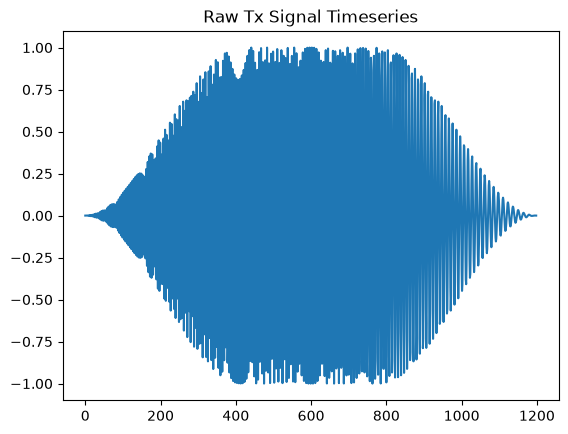

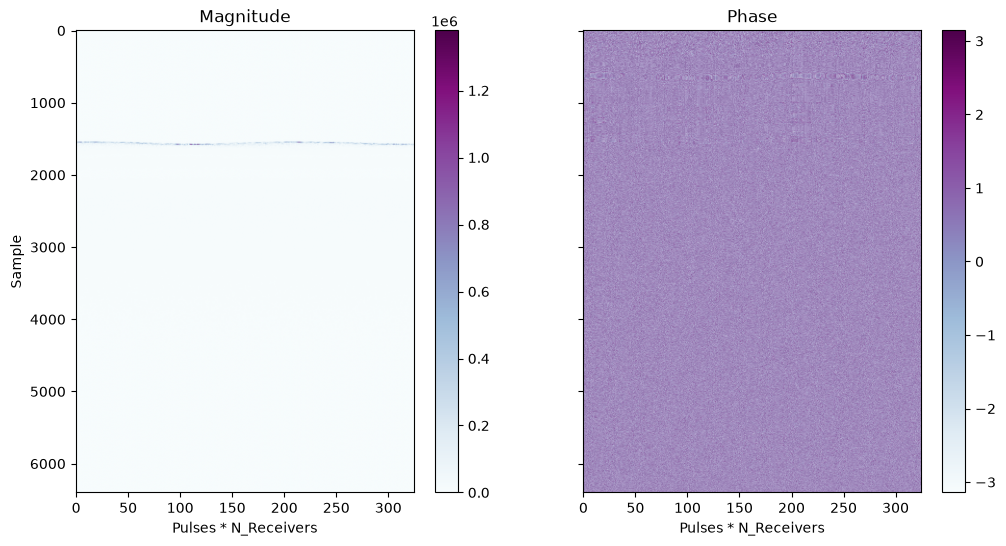

In [2]:
# filepath = Path("/home/amcdona4/Documents/frost-sas/mastodon_config/StaveData.hdf5")
filepath = None

if filepath is None:
    # print('Must specify stave data .json file on command line')
    # exit()
    import tkinter as tk
    from tkinter import filedialog

    root = tk.Tk()
    root.withdraw()

    filename = filedialog.askopenfilename()
else:
    filename = sys.argv[1]

data = read_stave_data_hdf5(filename)

print(data.signal.signal.shape)
print(data.data.shape)
print(data.data.dtype)


data.data = processing.match_filter(data.data, data.signal.signal)

plt.plot(data.signal.signal)
plt.title("Raw Tx Signal Timeseries")
plotHdf5(data)



In [3]:
print("Scipy Matched Filter Time")
%timeit processing.match_filter(data.data, data.signal.signal)
print("Numba Matched Filter")
%timeit processing.match_filter_numba(data.data, data.signal.signal)

Scipy Matched Filter Time
69.2 ms ± 448 μs per loop (mean ± std. dev. of 7 runs, 10 loops each)
Numba Matched Filter
194 ms ± 7.41 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)
